# M4 track: Co-Interactive joint model for intent detection and slot filling (MASSIVE 1.0 en-US)

**Owner:** Nicholas (M4 track, Stage 2 candidate). **Status:** Stage 2 exploration notebook, to be merged into `main.ipynb`.

**AI collaboration:** this notebook was written together with Claude (Anthropic, Claude Opus 5.5) as part of the
Stage 2 AI collaboration. The chat is exported to `ai_collaboration.md`. Stage 1 is **not** in this notebook.

**Question this notebook answers:** does letting the two tasks exchange information in *both* directions
(slots → intent and intent → slots) beat the current best Stage 2 model, a BiLSTM-CRF with a character CNN?

Why it matters: on validation, the current best models are already at about 81-82 slot F1, close to the pretrained
XLM-R baseline in the MASSIVE paper (78.7 test), but intent accuracy is about 2 points behind it (87 vs 88-89).
Resa's runs showed that a one-way intent → slot gate did **not** help (-0.33). M4 tests the other direction: slot
evidence such as `[time : five am]` should help the intent `alarm_set`.

**Fair comparison.** Sections 1-6 reuse the shared pipeline from `full_version_resa.ipynb` (same data checks,
tokenizer, vocabulary, evaluation functions, CRF, character CNN and training loop), so every number here is
computed exactly like the team's other Stage 2 numbers. The reference model is re-trained here with the same seeds.

| Section | Content |
|---|---|
| 0 | Setup and configuration |
| 1 | Load and verify the dataset |
| 2 | Text processing and shared evaluation functions (with unit tests) |
| 3 | Vocabulary, labels, GloVe embedding matrix, characters |
| 4 | Building blocks: CRF (tested against brute force), character CNN |
| 5 | The M4 model family (reference BiLSTM-CRF, Co-Interactive, Stack-Propagation) |
| 6 | Training and evaluation utilities |
| 7 | Experiments on validation (3 seeds each) and the selection rule |
| 8 | Official training run of the selected configuration, reload, single test evaluation |
| 9 | Error analysis: what M4 fixes and breaks compared with the reference |

## 0. Setup and configuration

In [1]:
import json
import math
import os
import platform
import random
import re
import shutil
import tarfile
import time
import urllib.request
import zipfile
import itertools
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seqeval.metrics
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader

try:
    from IPython.display import display
except ImportError:          # plain python: print instead
    display = print

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


print(f"python      {platform.python_version()}")
print(f"torch       {torch.__version__}")
print(f"device      {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

python      3.12.0
torch       2.11.0+cu128
device      cuda (NVIDIA GeForce RTX 4070 Laptop GPU)


In [2]:
# ---- Paths (runs/ and data/ are git-ignored) ----
DATA_DIR = Path("data")
OUT_DIR = Path("runs") / "m4"
CKPT_DIR, FIG_DIR = OUT_DIR / "checkpoints", OUT_DIR / "figures"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

MASSIVE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
MASSIVE_TAR = DATA_DIR / "amazon-massive-dataset-1.0.tar.gz"
MASSIVE_JSONL = DATA_DIR / "en-US.jsonl"
GLOVE_URLS = ["https://nlp.stanford.edu/data/glove.6B.zip",
              "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"]
GLOVE_ZIP, GLOVE_TXT = DATA_DIR / "glove.6B.zip", DATA_DIR / "glove.6B.300d.txt"
EMB_DIM = 300

EXPECTED_SPLITS = {"train": 11_514, "dev": 2_033, "test": 2_974}
PARAM_CAP = 20_000_000

# ---- Training recipe: identical to the team's Stage 2 (full_version_resa.ipynb) ----
BASE_CFG = dict(
    hidden=256, layers=2, dropout=0.3, word_dropout=0.1, wd_alpha=0.0,
    lr=1e-3, weight_decay=1e-2, batch_size=32, grad_clip=5.0, lr_schedule="plateau",
    char_cnn=True, crf=True, slot_loss_weight=1.0, label_smoothing=0.0,
    interaction="none",                                   # the reference BiLSTM-CRF
    label_att=True, coint_layers=1, d_model=256, heads=4, ffn_mult=2,   # used by interaction="coint"
)
MAX_EPOCHS = 60
PATIENCE = 8                 # early stopping on the validation selection score
EVAL_BATCH_SIZE = 256
SEEDS = [42, 43, 44]         # same seeds as the team's Stage 2 development runs
OFFICIAL_SEED = 42

# QUICK=1 only checks that every cell runs (tiny training budget, 1 seed). Results are meaningless in that mode.
QUICK = os.environ.get("M4_QUICK", "0") == "1"
if QUICK:
    MAX_EPOCHS, SEEDS = 2, [42]
    print("QUICK MODE: smoke test only, numbers are not results")

## 1. Load and verify the dataset

MASSIVE 1.0, file `1.0/data/en-US.jsonl`, split by the existing `partition` field. Nothing is added, removed or moved.

In [3]:
def download(url, dest):
    dest = Path(dest)
    if dest.exists():
        return dest
    tmp = dest.with_name(dest.name + ".part")
    print(f"downloading {url}")
    with urllib.request.urlopen(url, timeout=60) as response, open(tmp, "wb") as f:
        shutil.copyfileobj(response, f, length=1 << 20)
    tmp.rename(dest)
    return dest


if not MASSIVE_JSONL.exists():
    download(MASSIVE_URL, MASSIVE_TAR)
    with tarfile.open(MASSIVE_TAR, "r:gz") as tar:
        member = next(m for m in tar.getmembers() if m.name.endswith("1.0/data/en-US.jsonl"))
        with tar.extractfile(member) as src, open(MASSIVE_JSONL, "wb") as dst:
            shutil.copyfileobj(src, dst)

with open(MASSIVE_JSONL, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]
splits = {name: [r for r in records if r["partition"] == name] for name in EXPECTED_SPLITS}
for name, expected in EXPECTED_SPLITS.items():
    print(f"{name:5s}: {len(splits[name]):,} examples")
    assert len(splits[name]) == expected
assert sum(len(v) for v in splits.values()) == 16_521
assert all(r["locale"] == "en-US" for r in records)
print("split sizes verified: 11,514 / 2,033 / 2,974")

downloading https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz
train: 11,514 examples
dev  : 2,033 examples
test : 2,974 examples
split sizes verified: 11,514 / 2,033 / 2,974


## 2. Text processing and shared evaluation functions

Unchanged from the shared pipeline. Gold slots are parsed from `annot_utt` and aligned to `utt` by character
offsets; tokens use the Penn-Treebank-style split (`today's` → `today` `'s`) that the team chose because it is the
only tokenizer whose decoded gold tags reproduce 100% of the gold slots. Slot micro F1 is computed on
`(slot type, span text)` pairs, pooled over all utterances.

In [4]:
SLOT_RE = re.compile(r"\[(\S+) : ([^\]]+)\]")
TOKEN_RE = re.compile(r"\w+(?=n't\b)|n't\b|'\w+|\w+|[^\w\s]")
TOKENIZER = "ptb_split"


def norm_ws(s):
    return " ".join(s.split())


def parse_annot(utt, annot):
    """Gold slots as [(type, span_text, char_start, char_end)], with offsets into utt."""
    slots, i, pos = [], 0, 0

    def skip_space(i):
        while i < len(utt) and utt[i].isspace():
            i += 1
        return i

    def consume(segment, i):
        for ch in segment:
            if ch.isspace():
                continue
            i = skip_space(i)
            if i >= len(utt) or utt[i].lower() != ch.lower():
                raise ValueError(f"annot_utt does not match utt: {utt!r} / {annot!r}")
            i += 1
        return i

    for m in SLOT_RE.finditer(annot):
        i = consume(annot[pos:m.start()], i)
        start = skip_space(i)
        i = consume(m.group(2), start)
        slots.append((m.group(1), norm_ws(utt[start:i]), start, i))
        pos = m.end()
    i = consume(annot[pos:], i)
    assert not utt[i:].strip()
    return slots


def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def bio_tags(tokens, slots):
    tags = ["O"] * len(tokens)
    for stype, _, s, e in slots:
        first = True
        for k, (_, ts, te) in enumerate(tokens):
            if ts < e and te > s and tags[k] == "O":
                tags[k] = ("B-" if first else "I-") + stype
                first = False
    return tags


def tags_to_spans(tags):
    """BIO tags -> [(type, first_token, last_token)]; a stray I-X starts a new span (CoNLL rule)."""
    spans, k = [], 0
    while k < len(tags):
        if tags[k] == "O":
            k += 1
            continue
        stype, start = tags[k][2:], k
        k += 1
        while k < len(tags) and tags[k] == "I-" + stype:
            k += 1
        spans.append((stype, start, k - 1))
    return spans


def spans_to_pairs(spans, tokens, utt):
    return Counter((stype, norm_ws(utt[tokens[a][1]:tokens[b][2]])) for stype, a, b in spans)


def intent_accuracy(gold, pred):
    assert len(gold) == len(pred) and len(gold) > 0
    return 100.0 * sum(g == p for g, p in zip(gold, pred)) / len(gold)


def slot_micro_prf(gold_pairs, pred_pairs):
    tp = fp = fn = 0
    for g, p in zip(gold_pairs, pred_pairs):
        hit = sum((g & p).values())
        tp += hit
        fp += sum(p.values()) - hit
        fn += sum(g.values()) - hit
    denom = 2 * tp + fp + fn
    return dict(f1=100.0 * 2 * tp / denom if denom else 100.0,
                precision=100.0 * tp / (tp + fp) if tp + fp else 0.0,
                recall=100.0 * tp / (tp + fn) if tp + fn else 0.0, tp=tp, fp=fp, fn=fn)


def selection_score(intent_acc, slot_f1):
    """Checkpoint and model selection score (team choice): mean of intent accuracy and slot micro F1."""
    return (intent_acc + slot_f1) / 2


def score_predictions(examples, pred_intents, pred_tags):
    gold_int = [ex["intent"] for ex in examples]
    gold_pairs = [ex["gold_pairs"] for ex in examples]
    pred_pairs = [spans_to_pairs(tags_to_spans(t), ex["tokens"], ex["utt"]) for ex, t in zip(examples, pred_tags)]
    acc = intent_accuracy(gold_int, pred_intents)
    prf = slot_micro_prf(gold_pairs, pred_pairs)
    em = 100.0 * sum(gi == pi and gp == pp for gi, pi, gp, pp
                     in zip(gold_int, pred_intents, gold_pairs, pred_pairs)) / len(examples)
    return dict(intent_acc=acc, slot_f1=prf["f1"], slot_precision=prf["precision"], slot_recall=prf["recall"],
                exact_match=em, score=selection_score(acc, prf["f1"]))


# ---- Unit tests (same cases as the shared notebook) ----
def _pred(utt, tags):
    toks = tokenize(utt)
    return spans_to_pairs(tags_to_spans(tags), toks, utt)


def _f1(gold, pred):
    return round(slot_micro_prf(gold, pred)["f1"], 4)


_U = "wake me up at five am this week"
_G = Counter({("time", "five am"): 1, ("date", "this week"): 1})
assert _f1([_G], [_pred(_U, "O O O O B-time I-time B-date I-date".split())]) == 100.0
assert _f1([_G], [_pred(_U, "O O O O B-time O B-date I-date".split())]) == 50.0       # boundary error
assert _f1([_G], [_pred(_U, "O O O O B-date I-date B-date I-date".split())]) == 50.0  # type error
assert _f1([_G], [_pred(_U, "O O O O B-time I-time O O".split())]) == round(100 * 2 / 3, 4)
assert _f1([_G], [_pred(_U, "B-person O O O B-time I-time B-date I-date".split())]) == 80.0
assert _f1([Counter()], [Counter()]) == 100.0
_S3 = parse_annot("what is on today's schedule", "what is on [date : today]'s schedule")
assert _S3 == [("date", "today", 11, 16)]
_gt = [["O", "O", "O", "O", "B-time", "I-time", "B-date", "I-date"]]
_pt = [["O", "O", "O", "O", "B-time", "O", "B-date", "I-date"]]
assert round(100 * seqeval.metrics.f1_score(_gt, _pt), 4) == _f1([_G], [_pred(_U, _pt[0])])
print("evaluation unit tests passed")

evaluation unit tests passed


## 3. Vocabulary, labels, GloVe embedding matrix, characters

Everything is built from the **training split only**. Words outside the training vocabulary become `<unk>` at test
time. GloVe 6B 300d rows are kept only for training words (1.54M parameters, counted in the total).

In [5]:
PAD, UNK, IGNORE = 0, 1, -100


def build_examples(split_records):
    out = []
    for r in split_records:
        slots = parse_annot(r["utt"], r["annot_utt"])
        toks = tokenize(r["utt"])
        out.append(dict(id=r["id"], utt=r["utt"], intent=r["intent"], scenario=r["scenario"], tokens=toks,
                        words=[t[0].lower() for t in toks], tags=bio_tags(toks, slots),
                        gold_pairs=Counter((s[0], s[1]) for s in slots)))
    return out


EXAMPLES = {name: build_examples(recs) for name, recs in splits.items()}
_missed = sum(spans_to_pairs(tags_to_spans(ex["tags"]), ex["tokens"], ex["utt"]) != ex["gold_pairs"]
              for ex in EXAMPLES["train"])
assert _missed == 0, "tokenizer cannot represent some gold slots"

word_counts = Counter(w for ex in EXAMPLES["train"] for w in ex["words"])
ITOS = ["<pad>", "<unk>"] + [w for w, _ in word_counts.most_common()]
STOI = {w: i for i, w in enumerate(ITOS)}
V = len(ITOS)
ID2INTENT = sorted({ex["intent"] for ex in EXAMPLES["train"]})
INTENT2ID = {x: i for i, x in enumerate(ID2INTENT)}
SLOT_TYPES = sorted({t[2:] for ex in EXAMPLES["train"] for t in ex["tags"] if t != "O"})
ID2TAG = ["O"] + [f"{p}-{s}" for s in SLOT_TYPES for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(ID2TAG)}
N_INTENTS, N_TAGS = len(ID2INTENT), len(ID2TAG)
print(f"vocabulary V = {V:,}; intents = {N_INTENTS}; slot types = {len(SLOT_TYPES)}; BIO tags = {N_TAGS}")
assert (N_INTENTS, len(SLOT_TYPES)) == (60, 55)

# ---- Characters (training words only) ----
MAX_WORD_LEN = 20
CHAR_ITOS = ["<pad>", "<unk>"] + sorted({ch for ex in EXAMPLES["train"] for w in ex["words"] for ch in w})
CHAR2ID = {c: i for i, c in enumerate(CHAR_ITOS)}
N_CHARS = len(CHAR_ITOS)

# count of each vocabulary word in train (for count-based word dropout, an option from full_version_evan.ipynb)
WORD_COUNT = torch.tensor([0, 0] + [word_counts[w] for w in ITOS[2:]], dtype=torch.float)


def encode(ex):
    return dict(ids=[STOI.get(w, UNK) for w in ex["words"]],
                tag_ids=[TAG2ID.get(t, IGNORE) for t in ex["tags"]],
                intent_id=INTENT2ID.get(ex["intent"], IGNORE),
                char_ids=[[CHAR2ID.get(c, 1) for c in w[:MAX_WORD_LEN]] for w in ex["words"]])


DATASETS = {name: [(i, encode(ex)) for i, ex in enumerate(exs)] for name, exs in EXAMPLES.items()}
if QUICK:
    DATASETS["train"] = DATASETS["train"][:1500]

vocabulary V = 5,145; intents = 60; slot types = 55; BIO tags = 111


In [6]:
# GloVe rows for the training vocabulary, cached so later runs skip the 1 GB text file.
_cache = DATA_DIR / f"glove6b300_rows_{V}.npz"
if _cache.exists():
    _z = np.load(_cache, allow_pickle=False)
    assert list(_z["words"]) == ITOS
    EMB_MATRIX, _found = _z["matrix"], _z["found"]
else:
    if not GLOVE_TXT.exists():
        if not GLOVE_ZIP.exists():
            for url in GLOVE_URLS:
                try:
                    download(url, GLOVE_ZIP)
                    break
                except Exception as e:
                    print(f"  failed: {e}")
        with zipfile.ZipFile(GLOVE_ZIP) as z, z.open("glove.6B.300d.txt") as src, open(GLOVE_TXT, "wb") as dst:
            shutil.copyfileobj(src, dst, length=1 << 20)
    vecs = {}
    with open(GLOVE_TXT, encoding="utf-8") as f:
        for line in f:
            w, rest = line.rstrip("\n").split(" ", 1)
            if w in STOI:
                vecs[w] = np.asarray(rest.split(" "), dtype=np.float32)
    std = np.stack(list(vecs.values())).std()
    EMB_MATRIX = np.random.default_rng(0).normal(0.0, std, size=(V, EMB_DIM)).astype(np.float32)
    _found = np.zeros(V, dtype=bool)
    for w, vec in vecs.items():
        EMB_MATRIX[STOI[w]], _found[STOI[w]] = vec, True
    EMB_MATRIX[PAD] = 0.0
    np.savez(_cache, words=np.array(ITOS), matrix=EMB_MATRIX, found=_found)
print(f"training word types found in GloVe: {_found[2:].sum():,} / {V - 2:,}; embedding matrix {EMB_MATRIX.shape}")

downloading https://nlp.stanford.edu/data/glove.6B.zip
  failed: <urlopen error [WinError 10060] A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond>
downloading https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
training word types found in GloVe: 4,959 / 5,143; embedding matrix (5145, 300)


## 4. Building blocks: CRF and character CNN

Same CRF as the shared notebook: BIO constraints (an `I-X` may only follow `B-X` or `I-X`) are hard-coded as
-1e4 transition scores, so decoding never outputs an invalid tag sequence. The forward algorithm and Viterbi are
checked against brute-force enumeration before any training.

In [7]:
class CRF(nn.Module):
    def __init__(self, n_tags, allowed=None, start_allowed=None):
        super().__init__()
        self.n_tags = n_tags
        self.transitions = nn.Parameter(torch.empty(n_tags, n_tags).uniform_(-0.1, 0.1))
        self.start = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        self.end = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        allowed = torch.ones(n_tags, n_tags) if allowed is None else allowed.float()
        start_allowed = torch.ones(n_tags) if start_allowed is None else start_allowed.float()
        self.register_buffer("trans_penalty", (1 - allowed) * -1e4)
        self.register_buffer("start_penalty", (1 - start_allowed) * -1e4)

    def nll(self, emissions, tags, mask):
        """Negative log-likelihood of the gold tags, averaged over real tokens."""
        B, T, K = emissions.shape
        tags = torch.where(mask & (tags >= 0), tags, torch.zeros_like(tags))
        oh = F.one_hot(tags, K).to(emissions.dtype)
        maskf = mask.to(emissions.dtype)
        trans, start = self.transitions + self.trans_penalty, self.start + self.start_penalty
        gold = ((emissions * oh).sum(-1) * maskf).sum(1) + (oh[:, 0] * start).sum(-1)
        gold = gold + (torch.einsum("btk,kl,btl->bt", oh[:, :-1], trans, oh[:, 1:]) * maskf[:, 1:]).sum(1)
        last = mask.sum(1) - 1
        gold = gold + (oh[torch.arange(B, device=tags.device), last] * self.end).sum(-1)
        alpha = start + emissions[:, 0]
        for t in range(1, T):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + emissions[:, t]
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
        log_z = torch.logsumexp(alpha + self.end, dim=1)
        return (log_z - gold).sum() / maskf.sum()

    @torch.no_grad()
    def viterbi(self, emissions, mask):
        B, T, K = emissions.shape
        trans = self.transitions + self.trans_penalty
        score = self.start + self.start_penalty + emissions[:, 0]
        same = torch.arange(K, device=emissions.device).expand(B, K)
        backpointers = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
            m = mask[:, t].unsqueeze(1)
            score = torch.where(m, best + emissions[:, t], score)
            backpointers.append(torch.where(m, idx, same))
        last = (score + self.end).argmax(1)
        path = [last]
        for idx in reversed(backpointers):
            last = idx.gather(1, last.unsqueeze(1)).squeeze(1)
            path.append(last)
        return torch.stack(path[::-1], dim=1)


def bio_constraints(tag_names):
    K = len(tag_names)
    allowed, start = torch.zeros(K, K), torch.zeros(K)
    for j, tj in enumerate(tag_names):
        start[j] = not tj.startswith("I-")
        for i, ti in enumerate(tag_names):
            allowed[i, j] = (not tj.startswith("I-")) or (ti != "O" and ti[2:] == tj[2:])
    return allowed, start


def count_invalid_bio(tag_seqs):
    bad = 0
    for tags in tag_seqs:
        prev = "O"
        for t in tags:
            if t.startswith("I-") and (prev == "O" or prev[2:] != t[2:]):
                bad += 1
            prev = t
    return bad


def _brute(crf, em, length, gold):
    trans, start = crf.transitions + crf.trans_penalty, crf.start + crf.start_penalty
    scores = {}
    for path in itertools.product(range(crf.n_tags), repeat=length):
        s = start[path[0]] + em[0, path[0]] + crf.end[path[-1]]
        for t in range(1, length):
            s = s + trans[path[t - 1], path[t]] + em[t, path[t]]
        scores[path] = s
    log_z = torch.logsumexp(torch.stack(list(scores.values())), 0)
    return max(scores, key=lambda p: scores[p].item()), (log_z - scores[tuple(gold)]).item()


torch.manual_seed(0)
_names = ["O", "B-a", "I-a", "B-b", "I-b"]
for _constrained in (False, True):
    _crf = CRF(5, *bio_constraints(_names)) if _constrained else CRF(5)
    _em, _mask = torch.randn(2, 4, 5), torch.tensor([[1, 1, 1, 1], [1, 1, 1, 0]], dtype=torch.bool)
    _gold = torch.tensor([[1, 2, 0, 3], [3, 4, 0, -100]])
    _vit, _tot = _crf.viterbi(_em, _mask), 0.0
    for b, n in enumerate([4, 3]):
        _best, _nll = _brute(_crf, _em[b], n, _gold[b, :n].tolist())
        assert tuple(_vit[b, :n].tolist()) == _best
        _tot += _nll
    assert abs(_crf.nll(_em, _gold, _mask).item() - _tot / 7) < 1e-4
    if _constrained:
        _many = _crf.viterbi(torch.randn(64, 6, 5) * 3, torch.ones(64, 6, dtype=torch.bool))
        assert count_invalid_bio([[_names[k] for k in row] for row in _many.tolist()]) == 0
print("CRF unit tests passed")


class CharCNN(nn.Module):
    """Spelling features: 50-d character embeddings, 100 filters of width 3, max-pooled over each word."""

    def __init__(self, n_chars, dim=50, filters=100, kernel=3, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.conv = nn.Conv1d(dim, filters, kernel, padding=kernel // 2)
        self.out_dim = filters

    def forward(self, chars):
        B, T, L = chars.shape
        flat = chars.reshape(B * T, L)
        x = self.conv(self.dropout(self.emb(flat)).transpose(1, 2))
        x = x.masked_fill((flat == 0).unsqueeze(1), float("-inf"))
        return torch.relu(x.max(dim=2).values).reshape(B, T, -1)

CRF unit tests passed


## 5. The M4 model family

All variants share one front end and one training recipe, so a comparison changes exactly one thing:

`words → [GloVe 300-d ; char-CNN 100-d] → 2-layer BiLSTM (256 per direction) → H`

What happens after `H` is set by `interaction`:

| `interaction` | Intent | Slots | Information flow |
|---|---|---|---|
| `none` (**reference**, = the team's current best Stage 2) | max-pool(H) → linear | linear(H) → CRF | shared encoder only |
| `coint` (**M4**, Co-Interactive, Qin et al. 2021) | max-pool(H_I) → linear | linear(H_S) → CRF | intent ⇄ slots, every layer |
| `stackprop` (Stack-Propagation, Qin et al. 2019) | every word votes for an intent | linear([H ; word's intent distribution]) → CRF | intent → slots, at word level |

**M4 (`coint`) in detail.**
1. *Projection:* `H` (512-d) is projected to `d_model` (256) to keep the added layers small.
2. *Label attention* (`label_att=True`): the model learns one vector per intent (60) and per BIO tag (111). Each
   word attends over the intent vectors and over the tag vectors, giving an intent-flavoured copy `H_I` and a
   slot-flavoured copy `H_S` of the sentence (each = word + attention-weighted label vectors). With
   `label_att=False`, two plain linear layers make the two copies instead (ablation).
3. *Co-interactive layer* (repeated `coint_layers` times): the slot stream attends to the intent stream and the
   intent stream attends to the slot stream (multi-head attention, residual + LayerNorm); then a feed-forward layer
   reads both streams together (concatenated) and updates each one (residual + LayerNorm).
4. *Heads:* intent = max-pool over `H_I`, then a linear layer; slots = linear over `H_S`, then the CRF.

**Stack-Propagation in detail.** A linear layer predicts an intent for *every word*; the sentence intent is the
soft vote (sum of word log-probabilities). Each word's intent distribution is fed (through a small 64-d projection)
into its slot classifier, so slot decisions are conditioned on intent evidence at the word level. Training uses
the sentence intent as the target for every word.

**Loss** for all variants: intent cross-entropy (optional label smoothing) + `slot_loss_weight` × CRF negative
log-likelihood (averaged per token, so both terms are on the same scale).

In [8]:
class CoInteractiveLayer(nn.Module):
    def __init__(self, d, heads, d_ff, dropout):
        super().__init__()
        self.slot_from_intent = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.intent_from_slot = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln_s1, self.ln_i1, self.ln_s2, self.ln_i2 = (nn.LayerNorm(d) for _ in range(4))
        self.ffn_s = nn.Sequential(nn.Linear(2 * d, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d))
        self.ffn_i = nn.Sequential(nn.Linear(2 * d, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, h_i, h_s, mask, return_weights=False):
        pad = ~mask
        s_att, w_s = self.slot_from_intent(h_s, h_i, h_i, key_padding_mask=pad, need_weights=return_weights)
        i_att, w_i = self.intent_from_slot(h_i, h_s, h_s, key_padding_mask=pad, need_weights=return_weights)
        h_s = self.ln_s1(h_s + self.drop(s_att))
        h_i = self.ln_i1(h_i + self.drop(i_att))
        both = torch.cat([h_i, h_s], dim=-1)
        h_s2 = self.ln_s2(h_s + self.drop(self.ffn_s(both)))
        h_i2 = self.ln_i2(h_i + self.drop(self.ffn_i(both)))
        return (h_i2, h_s2, w_i, w_s) if return_weights else (h_i2, h_s2)


class JointM4(nn.Module):
    def __init__(self, hidden=256, layers=2, dropout=0.3, word_dropout=0.1, wd_alpha=0.0, char_cnn=True, crf=True,
                 interaction="none", label_att=True, coint_layers=1, d_model=256, heads=4, ffn_mult=2,
                 slot_loss_weight=1.0, label_smoothing=0.0, freeze_emb=False, sp_dim=64, **_unused):
        super().__init__()
        assert interaction in ("none", "coint", "stackprop")
        self.interaction, self.word_dropout, self.wd_alpha = interaction, word_dropout, wd_alpha
        self.slot_loss_weight, self.label_smoothing = slot_loss_weight, label_smoothing
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(EMB_MATRIX), freeze=freeze_emb, padding_idx=PAD)
        self.char_cnn = CharCNN(N_CHARS, dropout=dropout) if char_cnn else None
        in_dim = EMB_DIM + (self.char_cnn.out_dim if char_cnn else 0)
        self.emb_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(in_dim, hidden, num_layers=layers, bidirectional=True, batch_first=True,
                               dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        enc = 2 * hidden
        if interaction == "coint":
            self.proj = nn.Linear(enc, d_model)
            self.label_att = label_att
            if label_att:
                self.intent_labels = nn.Parameter(torch.randn(N_INTENTS, d_model) * d_model ** -0.5)
                self.slot_labels = nn.Parameter(torch.randn(N_TAGS, d_model) * d_model ** -0.5)
            else:
                self.to_intent, self.to_slot = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
            self.coint = nn.ModuleList([CoInteractiveLayer(d_model, heads, ffn_mult * d_model, dropout)
                                        for _ in range(coint_layers)])
            int_dim = slot_dim = d_model
        elif interaction == "stackprop":
            self.token_intent = nn.Linear(enc, N_INTENTS)
            self.intent_to_slot = nn.Linear(N_INTENTS, sp_dim, bias=False)
            int_dim, slot_dim = None, enc + sp_dim
        else:
            int_dim = slot_dim = enc
        self.intent_head = nn.Linear(int_dim, N_INTENTS) if int_dim else None
        self.slot_head = nn.Linear(slot_dim, N_TAGS)
        self.crf = CRF(N_TAGS, *bio_constraints(ID2TAG)) if crf else None

    def encode(self, batch):
        ids, lengths, mask = batch["ids"], batch["lengths"], batch["mask"]
        if self.training:
            if self.wd_alpha > 0:        # count-based: rare words are hidden more often
                cnt = WORD_COUNT.to(ids.device)[ids]
                p = self.wd_alpha / (self.wd_alpha + cnt)
            else:
                p = torch.full(ids.shape, self.word_dropout, device=ids.device)
            ids = ids.masked_fill((torch.rand(ids.shape, device=ids.device) < p) & mask & (ids > UNK), UNK)
        x = self.embedding(ids)
        if self.char_cnn is not None:
            x = torch.cat([x, self.char_cnn(batch["chars"])], dim=-1)
        x = self.emb_dropout(x)
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.encoder(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        return h

    @staticmethod
    def max_pool(h, mask):
        return h.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(dim=1).values

    def label_attention(self, h, labels):
        a = torch.softmax(h @ labels.t() / math.sqrt(h.size(-1)), dim=-1)
        return h + a @ labels

    def forward(self, batch, return_weights=False):
        mask = batch["mask"]
        h = self.encode(batch)
        out = {}
        if self.interaction == "coint":
            z = self.drop(self.proj(h))
            if self.label_att:
                h_i, h_s = self.label_attention(z, self.intent_labels), self.label_attention(z, self.slot_labels)
            else:
                h_i, h_s = self.to_intent(z), self.to_slot(z)
            weights = []
            for layer in self.coint:
                if return_weights:
                    h_i, h_s, w_i, w_s = layer(h_i, h_s, mask, return_weights=True)
                    weights.append((w_i, w_s))
                else:
                    h_i, h_s = layer(h_i, h_s, mask)
            out["intent"] = self.intent_head(self.drop(self.max_pool(h_i, mask)))
            out["slot"] = self.slot_head(self.drop(h_s))
            if return_weights:
                out["weights"] = weights
        elif self.interaction == "stackprop":
            tok = self.token_intent(self.drop(h))                               # (B, T, intents)
            logp = torch.log_softmax(tok, dim=-1)
            out["token_intent"] = tok
            out["intent"] = (logp * mask.unsqueeze(-1)).sum(1)                   # soft vote
            sp = self.intent_to_slot(logp.exp())
            out["slot"] = self.slot_head(self.drop(torch.cat([h, sp], dim=-1)))
        else:
            out["intent"] = self.intent_head(self.drop(self.max_pool(h, mask)))
            out["slot"] = self.slot_head(self.drop(h))
        return out

    def loss(self, out, batch):
        if self.interaction == "stackprop":
            mask = batch["mask"]
            target = batch["intents"].unsqueeze(1).expand_as(mask)[mask]
            intent_loss = F.cross_entropy(out["token_intent"][mask], target, label_smoothing=self.label_smoothing)
        else:
            intent_loss = F.cross_entropy(out["intent"], batch["intents"], label_smoothing=self.label_smoothing)
        if self.crf is not None:
            slot_loss = self.crf.nll(out["slot"], batch["tags"], batch["mask"])
        else:
            slot_loss = F.cross_entropy(out["slot"].reshape(-1, N_TAGS), batch["tags"].reshape(-1), ignore_index=IGNORE)
        return {"total": intent_loss + self.slot_loss_weight * slot_loss, "intent": intent_loss, "slot": slot_loss}

    def decode(self, out, batch):
        intents = out["intent"].argmax(-1).tolist()
        tags = (self.crf.viterbi(out["slot"], batch["mask"]) if self.crf is not None
                else out["slot"].argmax(-1)).tolist()
        return intents, [t[:n] for t, n in zip(tags, batch["lengths"].tolist())]


def build_model(cfg):
    return JointM4(**cfg)


def count_params(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))


def param_breakdown(model):
    rows = [(name, sum(p.numel() for p in m.parameters())) for name, m in model.named_children()]
    rows += [(name, p.numel()) for name, p in model.named_parameters(recurse=False)]
    total, trainable = count_params(model)
    rows = [(n, c) for n, c in rows if c > 0] + [("TOTAL", total), ("trainable", trainable)]
    return pd.DataFrame(rows, columns=["component", "parameters"]), total, trainable

## 6. Training and evaluation utilities

Same loop as the shared notebook: AdamW (no weight decay on embeddings, biases, LayerNorm or CRF scores), gradient
clipping, learning rate halved after 3 epochs without a better validation score, early stopping after 8, and the
checkpoint with the best validation selection score is kept. Every epoch is logged.

In [9]:
def collate(batch):
    idx, items = [b[0] for b in batch], [b[1] for b in batch]
    lengths = torch.tensor([len(x["ids"]) for x in items])
    T = int(lengths.max())
    L = max(len(c) for x in items for c in x["char_ids"])
    ids = torch.full((len(items), T), PAD, dtype=torch.long)
    tags = torch.full((len(items), T), IGNORE, dtype=torch.long)
    chars = torch.zeros((len(items), T, L), dtype=torch.long)
    for i, x in enumerate(items):
        n = len(x["ids"])
        ids[i, :n], tags[i, :n] = torch.tensor(x["ids"]), torch.tensor(x["tag_ids"])
        for t, c in enumerate(x["char_ids"]):
            chars[i, t, :len(c)] = torch.tensor(c)
    return dict(idx=torch.tensor(idx), ids=ids, lengths=lengths, mask=torch.arange(T)[None, :] < lengths[:, None],
                tags=tags, intents=torch.tensor([x["intent_id"] for x in items]), chars=chars)


def make_loader(split, batch_size, shuffle, seed=None):
    gen = None
    if shuffle:
        gen = torch.Generator()
        gen.manual_seed(seed)
    return DataLoader(DATASETS[split], batch_size=batch_size, shuffle=shuffle, collate_fn=collate, generator=gen)


def to_device(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}


@torch.no_grad()
def evaluate(model, split):
    model.eval()
    n = len(EXAMPLES[split])
    pred_int, pred_tags = [None] * n, [None] * n
    loss_sum, count = 0.0, 0
    for batch in make_loader(split, EVAL_BATCH_SIZE, shuffle=False):
        b = to_device(batch)
        out = model(b)
        loss_sum += model.loss(out, b)["total"].item() * len(batch["idx"])
        count += len(batch["idx"])
        ints, tag_seqs = model.decode(out, b)
        for i, it, ts in zip(batch["idx"].tolist(), ints, tag_seqs):
            pred_int[i], pred_tags[i] = ID2INTENT[it], [ID2TAG[t] for t in ts]
    metrics = score_predictions(EXAMPLES[split], pred_int, pred_tags)
    metrics["loss"] = loss_sum / count
    return metrics, pred_int, pred_tags


def make_optimizer(model, cfg):
    emb = {id(p) for m in model.modules() if isinstance(m, nn.Embedding) for p in m.parameters()}
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        use_decay = p.ndim >= 2 and id(p) not in emb and not name.startswith("crf") and "labels" not in name
        (decay if use_decay else no_decay).append(p)
    return torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                              {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])


def save_checkpoint(path, model, cfg, seed, row):
    torch.save(dict(model_state=model.state_dict(), cfg=cfg, seed=seed, epoch=row["epoch"], dev_metrics=dict(row),
                    vocab=ITOS, intents=ID2INTENT, tags=ID2TAG, tokenizer=TOKENIZER), path)


def load_checkpoint(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    assert ck["vocab"] == ITOS and ck["intents"] == ID2INTENT and ck["tags"] == ID2TAG
    model = build_model(ck["cfg"]).to(DEVICE)
    model.load_state_dict(ck["model_state"])
    model.eval()
    return model, ck


def run_training(cfg, seed, ckpt_path=None, verbose=True):
    set_seed(seed)
    model = build_model(cfg).to(DEVICE)
    total, _ = count_params(model)
    assert total <= PARAM_CAP, f"{total:,} parameters exceeds the cap"
    opt = make_optimizer(model, cfg)
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
             if cfg["lr_schedule"] == "plateau" else None)
    loader = make_loader("train", cfg["batch_size"], shuffle=True, seed=seed)
    history, best, bad, t_start = [], None, 0, time.time()
    if verbose:
        print(f"{'epoch':>5} | {'train loss':>10} | {'dev loss':>8} | {'dev intent':>10} | {'dev slot F1':>11} | "
              f"{'dev score':>9} | {'time':>6}")
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        model.train()
        sums, n = Counter(), 0
        for batch in loader:
            b = to_device(batch)
            losses = model.loss(model(b), b)
            opt.zero_grad(set_to_none=True)
            losses["total"].backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            for k, v in losses.items():
                sums[k] += v.item() * len(batch["idx"])
            n += len(batch["idx"])
        dev, _, _ = evaluate(model, "dev")
        row = dict(epoch=epoch, train_loss=sums["total"] / n, train_intent_loss=sums["intent"] / n,
                   train_slot_loss=sums["slot"] / n, dev_loss=dev["loss"], dev_intent_acc=dev["intent_acc"],
                   dev_slot_f1=dev["slot_f1"], dev_exact_match=dev["exact_match"], dev_score=dev["score"],
                   epoch_seconds=time.time() - t0, elapsed_seconds=time.time() - t_start,
                   lr=opt.param_groups[0]["lr"])
        history.append(row)
        if sched is not None:
            sched.step(row["dev_score"])
        improved = best is None or row["dev_score"] > best["dev_score"]
        if improved:
            best, bad = dict(row), 0
            if ckpt_path is not None:
                save_checkpoint(ckpt_path, model, cfg, seed, row)
        else:
            bad += 1
        if verbose:
            print(f"{epoch:>5} | {row['train_loss']:>10.4f} | {row['dev_loss']:>8.4f} | {row['dev_intent_acc']:>10.2f} | "
                  f"{row['dev_slot_f1']:>11.2f} | {row['dev_score']:>9.2f} | {row['epoch_seconds']:>5.1f}s "
                  f"{'*' if improved else ''}")
        if bad >= PATIENCE:
            if verbose:
                print(f"early stopping: no improvement for {PATIENCE} epochs")
            break
    return model, history, best


def plot_curves(history, best_epoch, title, path):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["epoch"], h["train_loss"], label="train loss")
    axes[0].plot(h["epoch"], h["dev_loss"], label="validation loss")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (intent CE + slot CRF NLL)"); axes[0].legend()
    axes[1].plot(h["epoch"], h["dev_intent_acc"], label="validation intent accuracy")
    axes[1].plot(h["epoch"], h["dev_slot_f1"], label="validation slot micro F1")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].legend()
    for ax in axes:
        ax.axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
        ax.grid(alpha=0.3)
    fig.suptitle(f"{title} (dashed line: selected epoch {best_epoch})")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


# Parameter budget of every variant tried below (all must be within 20M, word vectors included).
_rows = []
for _name, _cfg in [("reference BiLSTM-CRF", {}), ("M4, 1 co-interactive layer", {"interaction": "coint"}),
                    ("M4, 2 co-interactive layers", {"interaction": "coint", "coint_layers": 2}),
                    ("Stack-Propagation", {"interaction": "stackprop"})]:
    _t, _tr = count_params(build_model({**BASE_CFG, **_cfg}))
    _rows.append(dict(model=_name, total_parameters=f"{_t:,}", trainable=f"{_tr:,}", within_cap=_t <= PARAM_CAP))
display(pd.DataFrame(_rows))
display(param_breakdown(build_model({**BASE_CFG, "interaction": "coint"}))[0])

,model,total_parameters,trainable,within_cap
0,reference BiLSTM-CRF,"4,585,110","4,585,110",True
1,"M4, 1 co-interactive layer","6,032,790","6,032,790",True
2,"M4, 2 co-interactive layers","7,349,142","7,349,142",True
3,Stack-Propagation,"4,596,054","4,596,054",True


,component,parameters
0,embedding,1543500
1,char_cnn,16800
2,encoder,2924544
3,proj,131328
4,coint,1316352
5,intent_head,15420
6,slot_head,28527
7,crf,12543
8,intent_labels,15360
9,slot_labels,28416


## 7. Experiments on validation

Each configuration is trained with the same 3 seeds; we compare **mean validation selection scores**
(mean of intent accuracy and slot F1). The test split is not touched in this section.

**Keep rule (same as the team's Stage 2 protocol):** a change counts only if its mean score beats the
configuration it is compared with by more than `2 × sqrt(2/3) × σ`, twice the standard error of a difference
between two 3-seed means. σ is the pooled seed standard deviation over all configurations in this section
(more stable than one configuration's 3 seeds).

Experiments, in order:
1. **R** - reference BiLSTM-CRF (char-CNN + CRF + LR decay), the team's current best Stage 2 model.
2. **M4-1L** - Co-Interactive, label attention, 1 layer. *The main question.*
3. **M4-2L** - 2 co-interactive layers: does more interaction help or overfit?
4. **M4-noLA** - 1 layer without label attention: is the label attention doing anything?
5. **SP** - Stack-Propagation: a lighter, word-level way to share intent information.
6. **best + reg** - the best of 2-5 plus label smoothing 0.1 and count-based word dropout (α = 0.75), the two
   regularisers that helped intent in `full_version_evan.ipynb`.
7. **R + reg** - the same regularisers on the reference, so (6) is compared fairly.

Results are cached in `runs/m4/experiments.json`, so a crashed session resumes instead of retraining
(cached rows are labelled as such).

In [10]:
EXP_CACHE = OUT_DIR / ("experiments_quick.json" if QUICK else "experiments.json")
EXPERIMENTS = json.loads(EXP_CACHE.read_text()) if EXP_CACHE.exists() else {}
REG = {"label_smoothing": 0.1, "wd_alpha": 0.75}


def cfg_key(cfg, seed):
    return json.dumps({"cfg": cfg, "seed": seed}, sort_keys=True)


def run_seeds(name, change):
    cfg = {**BASE_CFG, **change}
    rows = []
    for s in SEEDS:
        key = cfg_key(cfg, s)
        cached = key in EXPERIMENTS
        if not cached:
            t0 = time.time()
            m, hist, best = run_training(cfg, s, verbose=False)
            del m
            EXPERIMENTS[key] = dict(best, epochs_run=len(hist), minutes=(time.time() - t0) / 60,
                                    sec_per_epoch=np.mean([h["epoch_seconds"] for h in hist]))
            EXP_CACHE.write_text(json.dumps(EXPERIMENTS, indent=1))
        r = EXPERIMENTS[key]
        rows.append(r)
        print(f"  {name:12s} seed {s}: intent {r['dev_intent_acc']:.2f} | slot F1 {r['dev_slot_f1']:.2f} | "
              f"score {r['dev_score']:.2f} | best epoch {r['epoch']}/{r['epochs_run']} | {r['minutes']:.1f} min"
              + (" (cached)" if cached else ""))
    d = pd.DataFrame(rows)
    return dict(experiment=name, change=json.dumps(change), params=count_params(build_model(cfg))[0],
                intent_mean=d.dev_intent_acc.mean(), intent_std=d.dev_intent_acc.std(ddof=1),
                slot_f1_mean=d.dev_slot_f1.mean(), slot_f1_std=d.dev_slot_f1.std(ddof=1),
                exact_mean=d.dev_exact_match.mean(),
                score_mean=d.dev_score.mean(), score_std=d.dev_score.std(ddof=1),
                scores=list(d.dev_score), best_epochs=" / ".join(str(int(e)) for e in d.epoch),
                minutes=d.minutes.sum())


RESULTS = {}
PLAN = [
    ("R", {}),
    ("M4-1L", {"interaction": "coint"}),
    ("M4-2L", {"interaction": "coint", "coint_layers": 2}),
    ("M4-noLA", {"interaction": "coint", "label_att": False}),
    ("SP", {"interaction": "stackprop"}),
]
for name, change in PLAN:
    RESULTS[name] = run_seeds(name, change)

# best interaction variant on validation, then the regularisers on it and on the reference
best_variant = max(["M4-1L", "M4-2L", "M4-noLA", "SP"], key=lambda k: RESULTS[k]["score_mean"])
best_change = dict(PLAN)[best_variant]
RESULTS[f"{best_variant} + reg"] = run_seeds(f"{best_variant} + reg", {**best_change, **REG})
RESULTS["R + reg"] = run_seeds("R + reg", REG)

  R            seed 42: intent 87.26 | slot F1 81.22 | score 84.24 | best epoch 38/46 | 34.4 min
  R            seed 43: intent 88.05 | slot F1 81.79 | score 84.92 | best epoch 38/46 | 14.0 min
  R            seed 44: intent 86.92 | slot F1 80.85 | score 83.88 | best epoch 21/29 | 5.4 min
  M4-1L        seed 42: intent 88.10 | slot F1 81.10 | score 84.60 | best epoch 34/42 | 10.1 min
  M4-1L        seed 43: intent 86.92 | slot F1 81.26 | score 84.09 | best epoch 37/45 | 11.4 min
  M4-1L        seed 44: intent 87.01 | slot F1 80.60 | score 83.80 | best epoch 31/39 | 9.9 min
  M4-2L        seed 42: intent 86.28 | slot F1 78.97 | score 82.62 | best epoch 60/60 | 16.8 min
  M4-2L        seed 43: intent 86.77 | slot F1 79.09 | score 82.93 | best epoch 46/54 | 14.7 min
  M4-2L        seed 44: intent 87.06 | slot F1 79.33 | score 83.20 | best epoch 48/56 | 15.4 min
  M4-noLA      seed 42: intent 87.31 | slot F1 79.42 | score 83.36 | best epoch 52/60 | 14.0 min
  M4-noLA      seed 43: intent 8

In [11]:
def pooled_std(results):
    """Pooled seed standard deviation of the selection score over all configurations."""
    num = sum((len(SEEDS) - 1) * r["score_std"] ** 2 for r in results.values() if len(SEEDS) > 1)
    return math.sqrt(num / (len(results) * (len(SEEDS) - 1))) if len(SEEDS) > 1 else float("nan")


SIGMA = pooled_std(RESULTS)
KEEP_MARGIN = 2 * math.sqrt(2 / len(SEEDS)) * SIGMA
ref_score = RESULTS["R"]["score_mean"]
table = pd.DataFrame(RESULTS.values())
# every model is compared with the reference, except "<best> + reg", which is compared with "R + reg"
compare_to = {k: ("R + reg" if k == f"{best_variant} + reg" else "R") for k in RESULTS}
table["vs"] = [compare_to[k] if k not in ("R",) else "" for k in RESULTS]
table["gain"] = [RESULTS[k]["score_mean"] - RESULTS[compare_to[k]]["score_mean"] if k != "R" else float("nan")
                 for k in RESULTS]
table["beats margin"] = [("" if k == "R" else ("yes" if g > KEEP_MARGIN else "no"))
                         for k, g in zip(RESULTS, table["gain"])]
show_cols = ["experiment", "params", "intent_mean", "intent_std", "slot_f1_mean", "slot_f1_std", "exact_mean",
             "score_mean", "score_std", "vs", "gain", "beats margin", "best_epochs", "minutes"]
display(table[show_cols].round(2))
table[show_cols].to_csv(OUT_DIR / "m4_validation_results.csv", index=False)
print(f"pooled seed std of the selection score: {SIGMA:.3f} -> keep margin {KEEP_MARGIN:.3f}")

,experiment,params,intent_mean,intent_std,slot_f1_mean,slot_f1_std,exact_mean,score_mean,score_std,vs,gain,beats margin,best_epochs,minutes
0,R,4585110,87.41,0.58,81.29,0.47,69.60,84.35,0.53,,NaN,,38 / 38 / 21,53.88
1,M4-1L,6032790,87.34,0.66,80.99,0.35,69.52,84.16,0.40,R,-0.18,no,34 / 37 / 31,31.41
2,M4-2L,7349142,86.70,0.40,79.13,0.18,67.68,82.92,0.29,R,-1.43,no,60 / 46 / 48,46.90
3,M4-noLA,6120598,86.98,0.45,79.81,0.34,68.52,83.40,0.15,R,-0.95,no,52 / 51 / 60,41.64
4,SP,4596054,87.67,0.30,81.79,0.44,70.06,84.73,0.10,R,0.38,no,33 / 45 / 50,29.94
5,SP + reg,4596054,87.10,0.10,81.51,0.47,69.91,84.30,0.19,R + reg,-0.55,no,30 / 24 / 15,19.06
6,R + reg,4585110,87.44,0.06,82.26,0.67,70.63,84.85,0.32,R,0.50,no,23 / 31 / 20,19.42


pooled seed std of the selection score: 0.313 -> keep margin 0.511


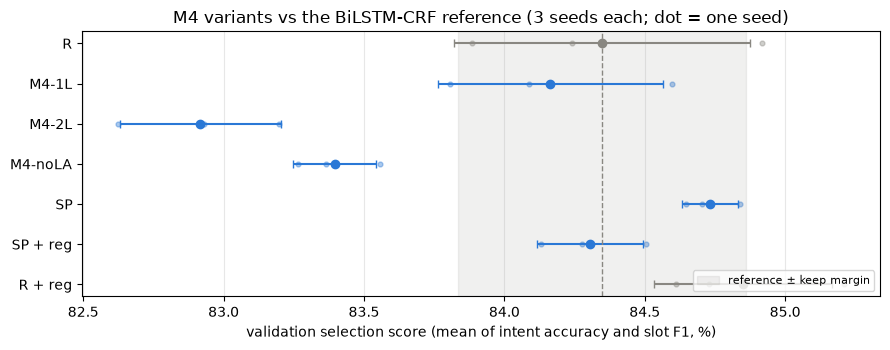

In [12]:
# One chart: mean validation score per configuration with each seed as a dot.
fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(RESULTS)
for y, k in enumerate(names):
    r = RESULTS[k]
    color = "#2a78d6" if k.startswith(("M4", "SP")) else "#898781"
    ax.errorbar(r["score_mean"], y, xerr=r["score_std"] if len(SEEDS) > 1 else 0, fmt="o", color=color, capsize=3)
    ax.scatter(r["scores"], [y] * len(r["scores"]), s=12, color=color, alpha=0.4)
ax.axvline(ref_score, color="#898781", linestyle="--", linewidth=1)
ax.axvspan(ref_score - KEEP_MARGIN, ref_score + KEEP_MARGIN, color="#898781", alpha=0.12, label="reference ± keep margin")
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("validation selection score (mean of intent accuracy and slot F1, %)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)
ax.set_title("M4 variants vs the BiLSTM-CRF reference (3 seeds each; dot = one seed)")
fig.tight_layout()
fig.savefig(FIG_DIR / "m4_validation.png", dpi=150)
plt.show()

**Selection.** The configuration for the official run is the one with the highest mean validation score among
all configurations above, *provided* it beats its comparison point by more than the keep margin; otherwise the
simpler model wins (Occam's razor: a change that does not clearly help is not worth its parameters).

In [13]:
order = sorted(RESULTS, key=lambda k: RESULTS[k]["score_mean"], reverse=True)
SELECTED = None
for k in order:
    if k == "R" or table.loc[list(RESULTS).index(k), "beats margin"] == "yes":
        SELECTED = k
        break
SELECTED_CHANGE = json.loads(RESULTS[SELECTED]["change"])
SELECTED_CFG = {**BASE_CFG, **SELECTED_CHANGE}
print(f"ranking by mean validation score: {order}")
print(f"selected for the official run: {SELECTED}  ->  changes from BASE_CFG: {SELECTED_CHANGE or '(none)'}")

ranking by mean validation score: ['R + reg', 'SP', 'R', 'SP + reg', 'M4-1L', 'M4-noLA', 'M4-2L']
selected for the official run: R  ->  changes from BASE_CFG: (none)


## 8. Official training run, reload and single test evaluation

The selected configuration is trained once with the official seed (42), logging every epoch; the best validation
checkpoint is saved, reloaded into a fresh model and evaluated on validation (must equal the logged best) and,
once, on test. The reference is also trained with seed 42 (validation only) so Section 9 can compare the two
models utterance by utterance.

epoch | train loss | dev loss | dev intent | dev slot F1 | dev score |   time
    1 |     3.4920 |   1.6393 |      66.50 |       41.86 |     54.18 |  11.8s *
    2 |     1.4494 |   0.9984 |      80.37 |       61.94 |     71.16 |  11.3s *
    3 |     1.0097 |   0.8510 |      83.92 |       67.78 |     75.85 |  11.3s *
    4 |     0.7991 |   0.7624 |      85.10 |       72.61 |     78.85 |  12.2s *
    5 |     0.6751 |   0.7624 |      85.19 |       74.35 |     79.77 |  11.9s *
    6 |     0.5697 |   0.7470 |      84.90 |       75.22 |     80.06 |  11.6s *
    7 |     0.5139 |   0.7764 |      85.34 |       76.13 |     80.73 |  11.6s *
    8 |     0.4361 |   0.7496 |      85.83 |       76.70 |     81.27 |  11.9s *
    9 |     0.4012 |   0.7577 |      85.98 |       77.97 |     81.98 |  12.1s *
   10 |     0.3556 |   0.7617 |      86.23 |       78.60 |     82.41 |  11.9s *
   11 |     0.3322 |   0.8018 |      85.49 |       78.61 |     82.05 |  11.5s 
   12 |     0.3117 |   0.7785 |      86.57 

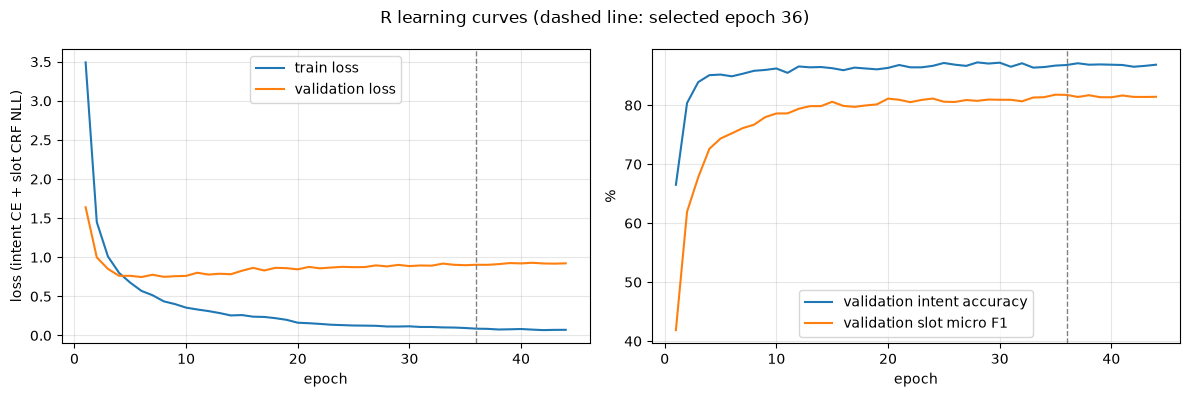

In [14]:
SEL_CKPT = CKPT_DIR / "m4_selected_best.pt"
sel_model, sel_history, sel_best = run_training(SELECTED_CFG, OFFICIAL_SEED, ckpt_path=SEL_CKPT, verbose=True)
del sel_model
pd.DataFrame(sel_history).to_csv(OUT_DIR / "m4_selected_history.csv", index=False)
print(f"\nselected checkpoint: epoch {sel_best['epoch']} (of {len(sel_history)} run); validation score "
      f"{sel_best['dev_score']:.2f} (intent {sel_best['dev_intent_acc']:.2f}, slot F1 {sel_best['dev_slot_f1']:.2f}); "
      f"file {SEL_CKPT}; training time {sel_history[-1]['elapsed_seconds'] / 60:.1f} min")
plot_curves(sel_history, sel_best["epoch"], f"{SELECTED} learning curves", FIG_DIR / "m4_selected_curves.png")

In [15]:
final_model, final_ck = load_checkpoint(SEL_CKPT)
final_dev, final_dev_int, final_dev_tags = evaluate(final_model, "dev")
assert abs(final_dev["score"] - final_ck["dev_metrics"]["dev_score"]) < 1e-6, "reloaded score differs from logged best"
final_test, final_test_int, final_test_tags = evaluate(final_model, "test")
total, trainable = count_params(final_model)
print(f"reloaded {SEL_CKPT} (epoch {final_ck['epoch']}): validation score {final_dev['score']:.4f} matches the log")
print(f"invalid BIO sequences predicted (dev / test): {count_invalid_bio(final_dev_tags)} / "
      f"{count_invalid_bio(final_test_tags)}")
FINAL_TABLE = pd.DataFrame([
    {"Model version": f"M4 track: {SELECTED}", "Split": "Validation", "Total # parameters": f"{total:,}",
     "Total # trainable parameters": f"{trainable:,}", "Intent accuracy (%)": f"{final_dev['intent_acc']:.2f}",
     "Slot micro-F1 (%)": f"{final_dev['slot_f1']:.2f}", "Number of epochs": str(final_ck["epoch"])},
    {"Model version": f"M4 track: {SELECTED}", "Split": "Test", "Total # parameters": "Same as above",
     "Total # trainable parameters": "Same as above", "Intent accuracy (%)": f"{final_test['intent_acc']:.2f}",
     "Slot micro-F1 (%)": f"{final_test['slot_f1']:.2f}", "Number of epochs": "Same as above"},
])
display(FINAL_TABLE)
print(f"test exact match (diagnostic): {final_test['exact_match']:.2f}")
json.dump(dict(selected=SELECTED, cfg=SELECTED_CFG, epoch=final_ck["epoch"], dev=final_dev, test=final_test,
               total_params=total, trainable_params=trainable, validation_table=table[show_cols].to_dict("records"),
               keep_margin=KEEP_MARGIN, sigma=SIGMA),
          open(OUT_DIR / "m4_final.json", "w"), indent=1, default=float)

reloaded runs\m4\checkpoints\m4_selected_best.pt (epoch 36): validation score 84.2814 matches the log
invalid BIO sequences predicted (dev / test): 0 / 0


,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,M4 track: R,Validation,"4,585,110","4,585,110",86.82,81.75,36
1,M4 track: R,Test,Same as above,Same as above,85.94,79.19,Same as above


test exact match (diagnostic): 67.85


## 9. Error analysis (validation only)

The reference BiLSTM-CRF and the best Co-Interactive model are both trained with seed 42 (if one of them is the
selected model, its official checkpoint is reused) and compared utterance by utterance on validation:
which intents does M4 fix or break, how do slot errors change, and do the fixes come from slot evidence?

In [16]:
def model_for(name):
    if name == SELECTED:
        return final_model
    path = CKPT_DIR / f"m4_{re.sub(r'[^A-Za-z0-9]+', '_', name)}_seed{OFFICIAL_SEED}.pt"
    if not path.exists():
        run_training({**BASE_CFG, **json.loads(RESULTS[name]["change"])}, OFFICIAL_SEED, ckpt_path=path, verbose=False)
    return load_checkpoint(path)[0]


best_coint = max(["M4-1L", "M4-2L", "M4-noLA"], key=lambda k: RESULTS[k]["score_mean"])
A_NAME, B_NAME = "R", best_coint
A_model, B_model = model_for(A_NAME), model_for(B_NAME)
A_dev, A_int, A_tags = evaluate(A_model, "dev")
B_dev, B_int, B_tags = evaluate(B_model, "dev")
dev_ex = EXAMPLES["dev"]


def slot_error_kinds(examples, pred_tags):
    kinds = Counter()
    for ex, pt in zip(examples, pred_tags):
        G = {(t, a, b) for t, a, b in tags_to_spans(ex["tags"])}
        P = {(t, a, b) for t, a, b in tags_to_spans(pt)}
        ov = lambda x, y: x[1] <= y[2] and y[1] <= x[2]
        for p in P - G:
            if any(g[1:] == p[1:] for g in G):
                kinds["wrong type"] += 1
            elif any(ov(g, p) and g[0] == p[0] for g in G):
                kinds["boundary"] += 1
            elif any(ov(g, p) for g in G):
                kinds["boundary + type"] += 1
            else:
                kinds["spurious"] += 1
        kinds["missed"] += sum(1 for g in G - P if not any(ov(g, p) for p in P))
    return kinds


summary = pd.DataFrame({
    A_NAME: {"intent acc": A_dev["intent_acc"], "slot F1": A_dev["slot_f1"], "exact match": A_dev["exact_match"],
             **slot_error_kinds(dev_ex, A_tags)},
    B_NAME: {"intent acc": B_dev["intent_acc"], "slot F1": B_dev["slot_f1"], "exact match": B_dev["exact_match"],
             **slot_error_kinds(dev_ex, B_tags)},
})
display(summary.round(2))

gold = [ex["intent"] for ex in dev_ex]
fixed = [i for i in range(len(gold)) if A_int[i] != gold[i] and B_int[i] == gold[i]]
broken = [i for i in range(len(gold)) if A_int[i] == gold[i] and B_int[i] != gold[i]]
print(f"intent: {B_NAME} fixes {len(fixed)} reference errors and introduces {len(broken)} new ones "
      f"(net {len(fixed) - len(broken):+d} of {len(gold)})")
has_slots = lambda i: len(dev_ex[i]["gold_pairs"]) > 0
print(f"  share of fixed utterances that contain gold slots: {100 * np.mean([has_slots(i) for i in fixed]):.0f}%  "
      f"(all dev: {100 * np.mean([has_slots(i) for i in range(len(gold))]):.0f}%)")

,R,M4-1L
intent acc,86.82,86.97
slot F1,81.75,80.54
exact match,69.45,68.67
missed,163.00,113.00
boundary,119.00,114.00
wrong type,56.00,77.00
spurious,134.00,187.00
boundary + type,37.00,56.00


intent: M4-1L fixes 64 reference errors and introduces 61 new ones (net +3 of 2033)
  share of fixed utterances that contain gold slots: 64%  (all dev: 68%)


In [17]:
def show(idx, n=6):
    rows = []
    for i in idx[:n]:
        ex = dev_ex[i]
        b_pairs = spans_to_pairs(tags_to_spans(B_tags[i]), ex["tokens"], ex["utt"])
        rows.append(dict(utt=ex["utt"], gold_intent=ex["intent"], R=A_int[i], M4=B_int[i],
                         M4_slots="; ".join(f"{t}: {s}" for (t, s) in b_pairs) or "-"))
    display(pd.DataFrame(rows))


print(f"Utterances whose intent {B_NAME} fixes:")
show(fixed)
print(f"Utterances whose intent {B_NAME} breaks:")
show(broken)

conf = Counter((gold[i], B_int[i]) for i in range(len(gold)) if B_int[i] != gold[i])
cross = sum(c for (g, p), c in conf.items() if g.split("_")[0] != p.split("_")[0])
print(f"{B_NAME} intent errors on dev: {sum(conf.values())}, of which {100 * cross / max(sum(conf.values()), 1):.0f}% "
      f"cross scenario. Most frequent confusions:")
display(pd.DataFrame([dict(gold=g, predicted=p, count=c) for (g, p), c in conf.most_common(10)]))

Utterances whose intent M4-1L fixes:


,utt,gold_intent,R,M4,M4_slots
0,cleaning is good dust is so bad do now your ma...,iot_cleaning,general_quirky,iot_cleaning,-
1,loop this track,music_settings,play_music,music_settings,-
2,set the volume to low,audio_volume_down,audio_volume_up,audio_volume_down,change_amount: to low
3,play the song immediately,play_music,play_audiobook,play_music,-
4,email me the lyrics to this song,music_query,music_dislikeness,music_query,-
5,what day of the week is thanksgiving,datetime_query,calendar_query,datetime_query,event_name: thanksgiving


Utterances whose intent M4-1L breaks:


,utt,gold_intent,R,M4,M4_slots
0,put on cannibal queen,play_music,play_music,music_settings,artist_name: cannibal queen
1,hey hey,general_greet,general_greet,general_quirky,-
2,olly death metal now,play_music,play_music,music_settings,music_genre: metal
3,play boogie in your butt by eddie murphy,play_music,play_music,play_audiobook,audiobook_name: boogie; person: eddie murphy
4,what are the lyrics to the song i will always ...,music_query,music_query,music_likeness,artist_name: dolly parton
5,please play leviathan,play_music,play_music,play_audiobook,audiobook_name: leviathan


M4-1L intent errors on dev: 265, of which 73% cross scenario. Most frequent confusions:


,gold,predicted,count
0,qa_factoid,general_quirky,11
1,play_music,play_audiobook,6
2,general_quirky,qa_definition,6
3,general_quirky,weather_query,5
4,general_quirky,cooking_recipe,5
5,general_quirky,qa_factoid,5
6,qa_factoid,qa_definition,4
7,general_quirky,news_query,4
8,general_quirky,calendar_set,4
9,calendar_query,recommendation_events,4


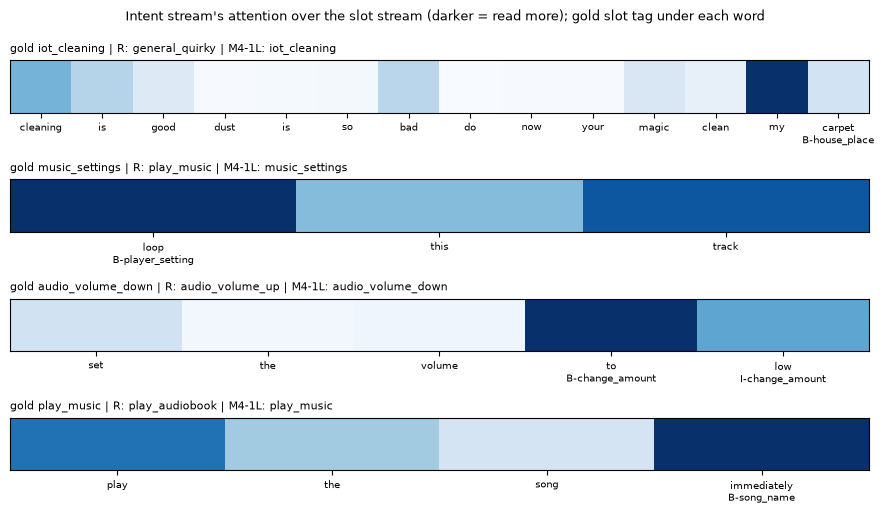

In [18]:
# What does the intent stream look at? Attention of the intent stream over the slot stream (last layer, mean of heads).
@torch.no_grad()
def intent_attention(model, i):
    model.eval()
    b = to_device(collate([DATASETS["dev"][i]]))
    out = model(b, return_weights=True)
    w_i = out["weights"][-1][0][0]                     # (T queries, T keys), averaged over heads
    return w_i.mean(0).cpu().numpy()                   # how much the intent stream reads each word's slot state


picks = [i for i in fixed if has_slots(i)][:4] or fixed[:4]
if picks and B_NAME.startswith("M4"):
    fig, axes = plt.subplots(len(picks), 1, figsize=(9, 1.3 * len(picks)))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, picks):
        w = intent_attention(B_model, i)
        words = dev_ex[i]["words"]
        ax.imshow(w[None, :], aspect="auto", cmap="Blues", vmin=0)
        ax.set_xticks(range(len(words)), [f"{w_}\n{t}" if t != "O" else w_ for w_, t in zip(words, dev_ex[i]["tags"])],
                      fontsize=7)
        ax.set_yticks([])
        ax.set_title(f"gold {dev_ex[i]['intent']} | R: {A_int[i]} | {B_NAME}: {B_int[i]}", fontsize=8, loc="left")
    fig.suptitle("Intent stream's attention over the slot stream (darker = read more); gold slot tag under each word",
                 fontsize=9)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "m4_intent_attention.png", dpi=150)
    plt.show()